# Fulfillment EDA

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

from pathlib import Path

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "00_common.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the Olist project folder.")
common_notebook = str(ROOT / "notebooks" / "00_common.ipynb")
%run "$common_notebook"
check_data(paths)

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'navy': '#17324D', 'teal': '#0F766E', 'blue': '#2563EB',
          'amber': '#D97706', 'red': '#B91C1C', 'gray': '#6B7280'}
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

## 1. Data checks before analysis

In [2]:
display(query('SELECT * FROM checks.required_checks ORDER BY check_id'))

,check_id,check_name,table_name,rows_tested,affected_count,expected_result
0,B001,Source row counts match the dataset,staging.source_control_totals,9,0,0 mismatched tables
1,B002,Order mart has one row per source order,marts.mart_order_fulfillment,99441,0,99441 rows and unique order_id
2,B003,Order-seller mart grain is unique,marts.mart_order_seller,100010,0,0 duplicate order_id × seller_id rows
3,B004,Order-seller mart reconciles to source pairs,marts.mart_order_seller,100010,0,Matches distinct source order_id × seller_id p...
4,B005,Order-category mart grain is unique,marts.mart_order_category,99470,0,0 duplicate order_id × category rows
5,B006,Gross item value reconciles,intermediate.int_order_items,1,0,Absolute difference <= 0.01
6,B007,Freight value reconciles,intermediate.int_order_items,1,0,Absolute difference <= 0.01
7,B008,Payment total reconciles,intermediate.int_order_payments,1,0,Absolute difference <= 0.01
8,B009,KPI numerators do not exceed denominators,marts.mart_monthly_fulfillment_kpi,20,0,0 invalid monthly rows
9,B010,Monthly KPI denominators are nonzero,marts.mart_monthly_fulfillment_kpi,20,0,0 monthly rows with zero denominators


## 2. Overall delivery performance

In [3]:
headline = query("""
SELECT
    SUM(total_order_count) AS primary_orders,
    SUM(delivered_order_count) AS delivered_orders,
    SUM(canceled_order_count) AS canceled_orders,
    SUM(unavailable_order_count) AS unavailable_orders,
    SUM(on_time_delivery_count) AS on_time_orders,
    SUM(delivery_sla_eligible_count) AS delivery_sla_eligible,
    SUM(on_time_delivery_count)::DOUBLE / SUM(delivery_sla_eligible_count)
        AS on_time_delivery_rate,
    SUM(handover_breach_count) AS handover_breaches,
    SUM(handover_sla_eligible_count) AS handover_sla_eligible,
    SUM(handover_breach_count)::DOUBLE / SUM(handover_sla_eligible_count)
        AS handover_breach_rate,
    SUM(reviewed_order_count)::DOUBLE / SUM(total_order_count)
        AS review_response_coverage
FROM marts.mart_monthly_fulfillment_kpi
""")
display(headline.T.rename(columns={0: 'value'}))

,value
primary_orders,"99,092.000"
delivered_orders,"96,211.000"
canceled_orders,580.000
unavailable_orders,602.000
on_time_orders,"89,672.000"
delivery_sla_eligible,"96,203.000"
on_time_delivery_rate,0.932
handover_breaches,"8,652.000"
handover_sla_eligible,"96,032.000"
handover_breach_rate,0.090


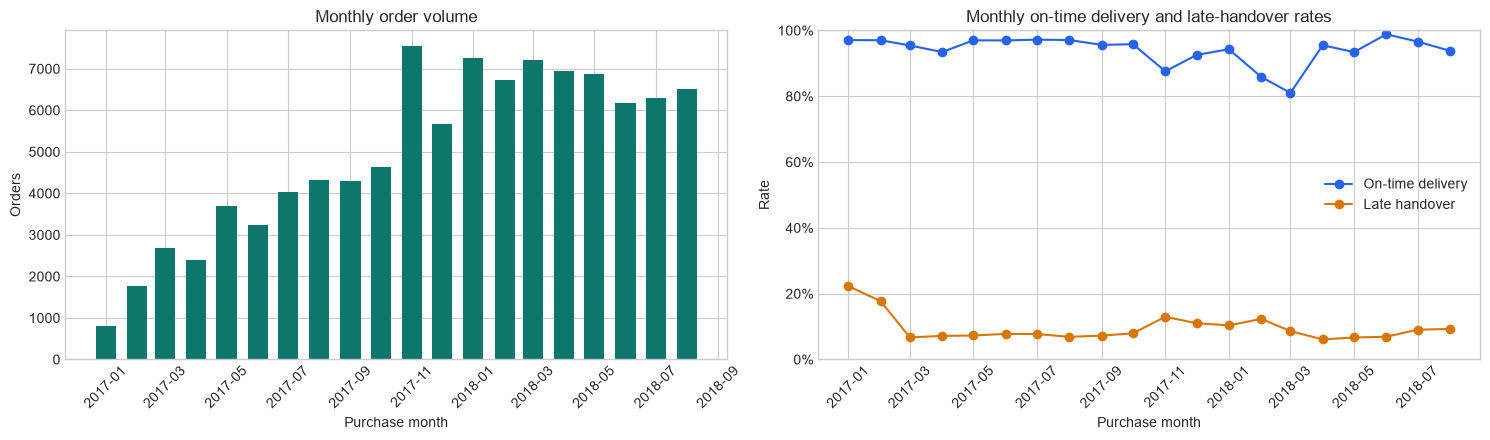

In [4]:
monthly = query("""
SELECT purchase_month, total_order_count, on_time_delivery_rate,
       handover_breach_rate, cancellation_rate, unavailable_rate
FROM marts.mart_monthly_fulfillment_kpi
ORDER BY purchase_month
""")
monthly['purchase_month'] = pd.to_datetime(monthly['purchase_month'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(monthly['purchase_month'], monthly['total_order_count'],
            width=20, color=COLORS['teal'])
axes[0].set(title='Monthly order volume', ylabel='Orders', xlabel='Purchase month')
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(monthly['purchase_month'], monthly['on_time_delivery_rate'],
             marker='o', label='On-time delivery', color=COLORS['blue'])
axes[1].plot(monthly['purchase_month'], monthly['handover_breach_rate'],
             marker='o', label='Late handover', color=COLORS['amber'])
axes[1].set(title='Monthly on-time delivery and late-handover rates', ylabel='Rate',
            xlabel='Purchase month', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=45)
axes[1].yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## 3. On-time delivery: comparing calendar dates

In [5]:
calendar_rule = query("""
SELECT
    COUNT(*) FILTER (
        WHERE is_delivery_sla_eligible
          AND order_delivered_customer_date::DATE = order_estimated_delivery_date::DATE
          AND order_delivered_customer_date > order_estimated_delivery_date
    ) AS all_period_promised_day_arrivals,
    COUNT(*) FILTER (
        WHERE is_primary_analysis_period
          AND is_delivery_sla_eligible
          AND order_delivered_customer_date::DATE = order_estimated_delivery_date::DATE
          AND order_delivered_customer_date > order_estimated_delivery_date
    ) AS primary_period_promised_day_arrivals,
    COUNT(*) FILTER (
        WHERE is_primary_analysis_period AND is_delivery_sla_eligible AND on_time_delivery
    ) AS primary_period_on_time_orders
FROM marts.mart_order_fulfillment
""")
display(calendar_rule)

,all_period_promised_day_arrivals,primary_period_promised_day_arrivals,primary_period_on_time_orders
0,1292,1291,89672


Promised delivery timestamps are all recorded at midnight. Comparing them with arrival timestamps would mark **1,291** orders that arrived on the promised day as late and lower on-time delivery to about **91.9%**. Comparing calendar dates gives **93.2%**.

## 4. Time spent in each delivery stage

,stage_name,eligible_order_count,excluded_order_count,p50_hours,p75_hours,p90_hours
0,Purchase to approval,98957,135,0.342,14.485,34.596
1,Approval to carrier handover,96003,3089,44.280,86.358,143.890
2,Carrier handover to customer delivery,96184,2908,170.505,288.859,453.871
3,Purchase to customer delivery,96204,2888,245.042,376.386,553.552


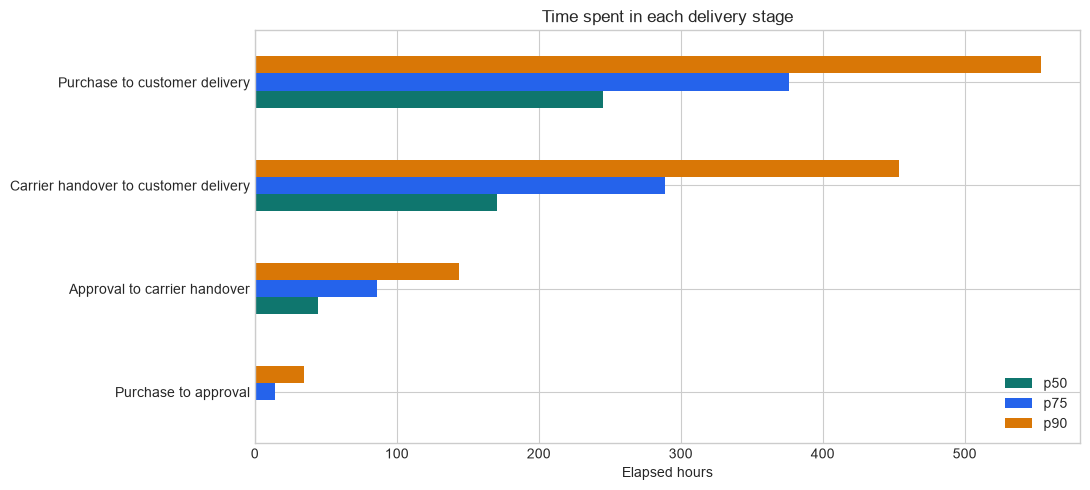

In [6]:
stages = query('SELECT * FROM analysis.fulfillment_stage_summary')
display(stages)

stage_plot = stages.set_index('stage_name')[['p50_hours', 'p75_hours', 'p90_hours']]
ax = stage_plot.plot.barh(
    figsize=(11, 5), color=[COLORS['teal'], COLORS['blue'], COLORS['amber']]
)
ax.set(title='Time spent in each delivery stage', xlabel='Elapsed hours', ylabel='')
ax.legend(['p50', 'p75', 'p90'], frameon=False)
plt.tight_layout()
plt.show()

Across all eligible orders, the median approval-to-handover stage is about **1.8 days** and the median handover-to-delivery stage about **7.1 days**. Section 10 compares the same stages for late and on-time orders.

## 5. Late handover vs late delivery

,failure_mode,order_count,average_review_score,reviewed_order_count
0,Handover met / Delivery on time,81692,4.330,81266
1,Handover breached / Delivery on time,6721,4.085,6670
2,Handover met / Delivery late,4708,2.272,4603
3,Handover breached / Delivery late,1809,2.268,1762


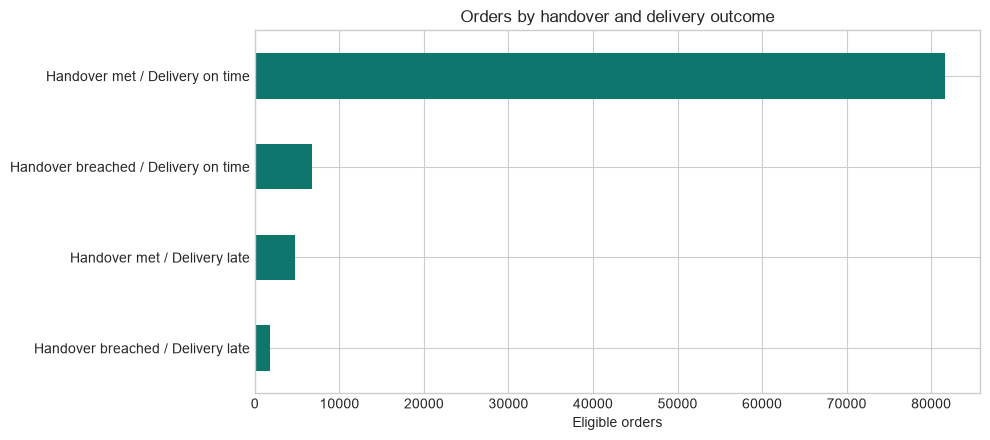

In [7]:
failure_modes = query("""
SELECT * FROM analysis.handover_delivery_failure_modes
ORDER BY order_count DESC
""")
display(failure_modes)

ax = failure_modes.sort_values('order_count').plot.barh(
    x='failure_mode', y='order_count', figsize=(10, 4.5),
    color=COLORS['teal'], legend=False
)
ax.set(title='Orders by handover and delivery outcome',
       xlabel='Eligible orders', ylabel='')
plt.tight_layout()
plt.show()

A late handover means the seller handed the order to the carrier after the item's shipping deadline. Orders with a late handover arrived late **21.2%** of the time, vs **5.4%** when the handover was on time. But of the **6,517** late single-seller orders where both can be checked, **72.2%** (4,708) were handed over on time, so handover timing alone does not explain most late deliveries.

## 6. Seller order volume and priority tiers

,value
minimum_seller_orders,30.000
watchlist_minimum_orders,20.000
minimum_seller_month_orders,5.000
minimum_active_months,2.000
minimum_breach_count,5.000
monthly_rate_gap,0.050
repeated_month_requirement,2.000
high_contribution_share,0.010
customer_warning_gap,0.050


,eligible_order_count
count,"2,932.000"
mean,32.753
std,104.793
min,1.000
50%,7.000
75%,22.000
90%,72.900
95%,129.000
99%,393.070
max,"1,813.000"


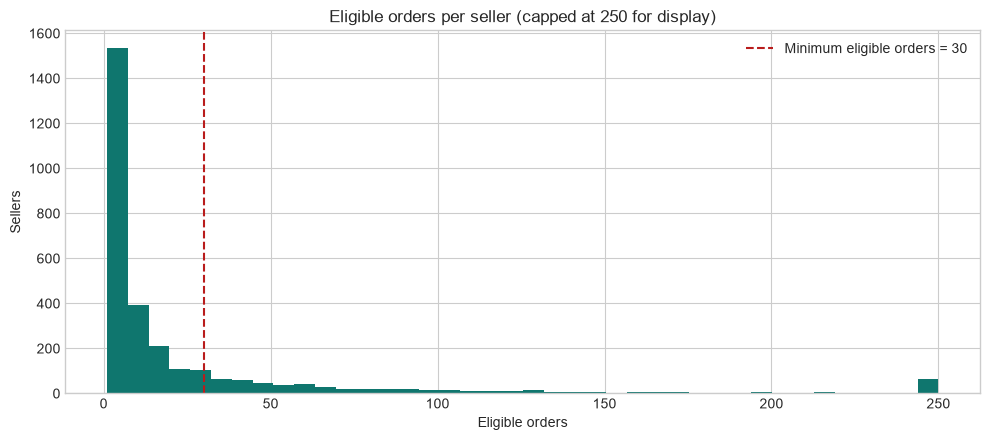

In [8]:
parameters = query('SELECT * FROM analysis.queue_parameters')
seller = query('SELECT * FROM analysis.agg_seller_performance')
display(parameters.T.rename(columns={0: 'value'}))
display(
    seller['eligible_order_count']
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

minimum_orders = int(parameters.loc[0, 'minimum_seller_orders'])
fig, ax = plt.subplots(figsize=(10, 4.5))
seller['eligible_order_count'].clip(upper=250).hist(
    bins=40, ax=ax, color=COLORS['teal']
)
ax.axvline(minimum_orders, color=COLORS['red'], linestyle='--',
           label=f'Minimum eligible orders = {minimum_orders}')
ax.set(title='Eligible orders per seller (capped at 250 for display)',
       xlabel='Eligible orders', ylabel='Sellers')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

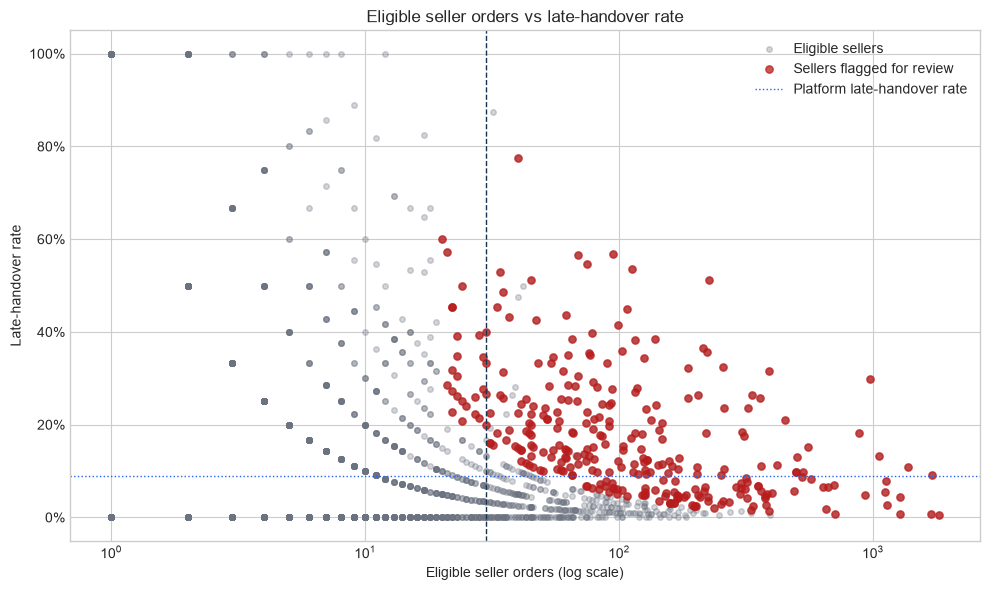

,seller_id,priority_tier,eligible_order_count,handover_breach_count,handover_breach_rate,repeated_breach_month_count,breach_delay_p90_hours,reason_codes
0,7c67e1448b00f6e969d365cea6b010ab,P1,970,289,0.298,18,138.755,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
1,1025f0e2d44d7041d6cf58b6550e0bfa,P1,884,161,0.182,5,181.048,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
2,4a3ca9315b744ce9f8e9374361493884,P1,1704,154,0.090,4,77.878,SUFFICIENT_VOLUME|HIGH_BREACH_CONTRIBUTION|REP...
3,1f50f920176fa81dab994f9023523100,P1,1368,150,0.110,7,38.613,SUFFICIENT_VOLUME|HIGH_BREACH_CONTRIBUTION|REP...
4,3d871de0142ce09b7081e2b9d1733cb1,P1,1056,139,0.132,4,51.738,SUFFICIENT_VOLUME|HIGH_BREACH_CONTRIBUTION|REP...
5,06a2c3af7b3aee5d69171b0e14f0ee87,P1,391,123,0.315,4,286.430,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
6,88460e8ebdecbfecb5f9601833981930,P1,227,116,0.511,7,349.681,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
7,53e4c6e0f4312d4d2107a8c9cddf45cd,P1,451,95,0.211,11,70.743,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
8,8160255418d5aaa7dbdc9f4c64ebda44,P1,360,93,0.258,5,155.685,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...
9,92eb0f42c21942b6552362b9b114707d,P1,334,88,0.263,11,89.529,SUFFICIENT_VOLUME|HIGH_BREACH_RATE|HIGH_BREACH...


In [9]:
queue = query("""
SELECT * FROM analysis.mart_seller_investigation_queue
ORDER BY priority_sort, handover_breach_count DESC, handover_breach_rate DESC
""")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(seller['eligible_order_count'], seller['handover_breach_rate'],
           s=16, alpha=0.30, color=COLORS['gray'], label='Eligible sellers')
ax.scatter(queue['eligible_order_count'], queue['handover_breach_rate'],
           s=28, alpha=0.75, color=COLORS['red'], label='Sellers flagged for review')
ax.axvline(minimum_orders, color=COLORS['navy'], linestyle='--', linewidth=1)
ax.axhline(seller['platform_handover_breach_rate'].iloc[0],
           color=COLORS['blue'], linestyle=':', linewidth=1,
           label='Platform late-handover rate')
ax.set_xscale('log')
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax.set(title='Eligible seller orders vs late-handover rate',
       xlabel='Eligible seller orders (log scale)', ylabel='Late-handover rate')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

display(queue[[
    'seller_id', 'priority_tier', 'eligible_order_count', 'handover_breach_count',
    'handover_breach_rate', 'repeated_breach_month_count',
    'breach_delay_p90_hours', 'reason_codes'
]].head(15))

Half of sellers have **7** or fewer eligible orders (75th percentile: 22), so sorting by late-handover rate would put very small sellers on top. The **70 P1** sellers have enough orders, late handovers repeated across months, and either a large share of all late handovers or long delays. Together they account for **2,815 of 8,652** late handovers (**32.5%**).

## 7. How the candidate count changes with thresholds

,minimum_orders,monthly_gap_pp,repeated_month_requirement,qualifying_seller_count
0,20,3.000,2,219
1,20,3.000,3,156
2,20,5.000,2,203
3,20,5.000,3,140
4,20,10.000,2,151
5,20,10.000,3,84
6,30,3.000,2,213
7,30,3.000,3,155
8,30,5.000,2,197
9,30,5.000,3,139


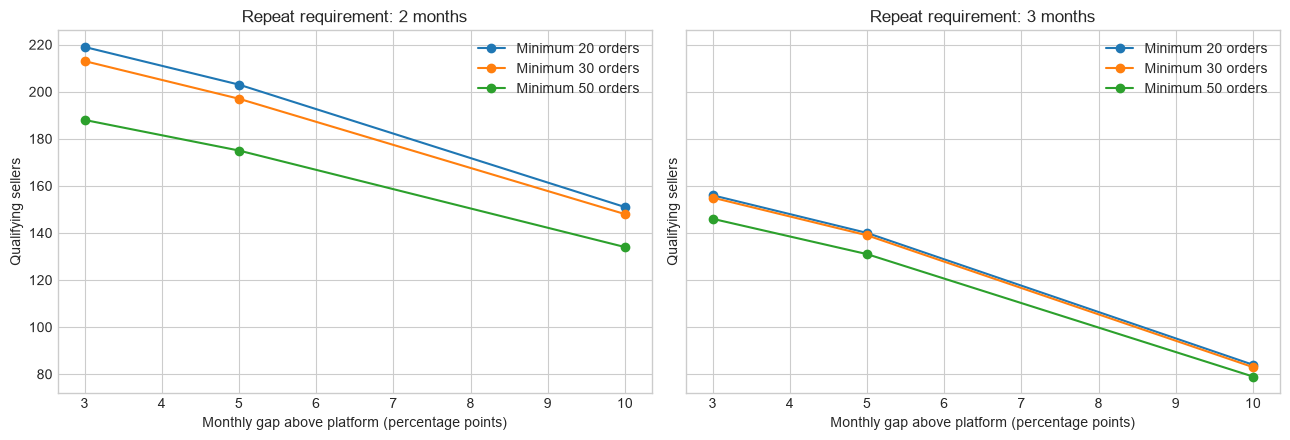

In [10]:
sensitivity = query("""
SELECT * FROM analysis.queue_threshold_sensitivity
ORDER BY minimum_orders, monthly_gap_pp, repeated_month_requirement
""")
display(sensitivity)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, repeat_requirement in zip(axes, [2, 3], strict=True):
    subset = sensitivity[
        sensitivity['repeated_month_requirement'] == repeat_requirement
    ]
    for minimum in sorted(subset['minimum_orders'].unique()):
        line = subset[subset['minimum_orders'] == minimum]
        ax.plot(line['monthly_gap_pp'], line['qualifying_seller_count'],
                marker='o', label=f'Minimum {minimum} orders')
    ax.set(title=f'Repeat requirement: {repeat_requirement} months',
           xlabel='Monthly gap above platform (percentage points)',
           ylabel='Qualifying sellers')
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 8. Late deliveries by seller state → customer state

,state_pair,eligible_delivery_order_count,late_delivery_order_count,late_delivery_rate,handover_eligible_order_count,handover_breach_count,handover_breach_rate
0,SP → SP,30254,1424,0.047,30508,2785,0.091
1,SP → RJ,8031,1147,0.143,8231,784,0.095
2,SP → MG,7307,391,0.054,7356,691,0.094
3,SP → BA,2275,297,0.131,2331,199,0.085
4,SP → RS,3530,238,0.067,3554,274,0.077
5,SP → SC,2300,222,0.097,2319,203,0.088
6,SP → ES,1443,180,0.125,1457,130,0.089
7,SP → PR,3069,138,0.045,3089,269,0.087
8,SP → CE,958,133,0.139,989,91,0.092
9,PR → RJ,948,117,0.123,966,113,0.117


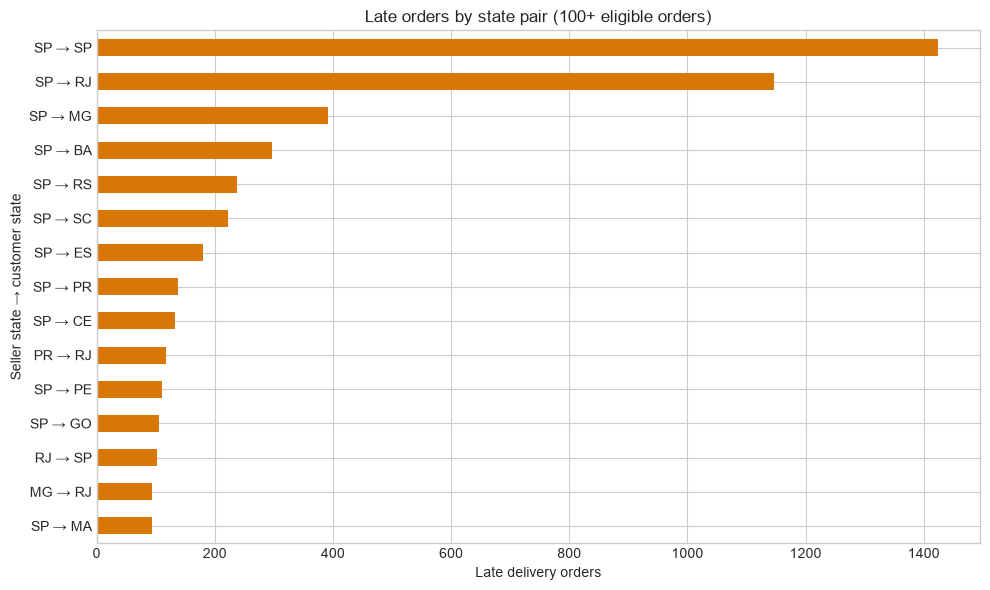

In [11]:
lanes = query("""
SELECT seller_state || ' → ' || customer_state AS state_pair,
       eligible_delivery_order_count, late_delivery_order_count, late_delivery_rate,
       handover_eligible_order_count, handover_breach_count, handover_breach_rate
FROM analysis.agg_state_lane_performance
WHERE eligible_delivery_order_count >= 100
ORDER BY late_delivery_order_count DESC, late_delivery_rate DESC
LIMIT 15
""")
display(lanes)

ax = lanes.sort_values('late_delivery_order_count').plot.barh(
    x='state_pair', y='late_delivery_order_count', figsize=(10, 6),
    color=COLORS['amber'], legend=False
)
ax.set(title='Late orders by state pair (100+ eligible orders)',
       xlabel='Late delivery orders', ylabel='Seller state → customer state')
plt.tight_layout()
plt.show()

These are seller state → customer state pairs, not actual carrier routes. SP → RJ orders arrived late **14.3%** of the time vs **4.7%** for SP → SP, while late-handover rates are close (**9.5%** vs **9.1%**). The carrier stage on pairs like SP → RJ is the first place to look; distance and product mix are not controlled.

## 9. Delivery delay and review scores

,delivery_group,delivery_sla_eligible_count,reviewed_order_count,review_response_coverage,average_review_score,low_review_rate
0,On time,89672,89182,0.995,4.291,0.092
1,Late 1-3 days,1869,1851,0.990,3.291,0.321
2,Late 4-7 days,1802,1748,0.970,2.103,0.677
3,Late 8+ days,2860,2779,0.972,1.697,0.793


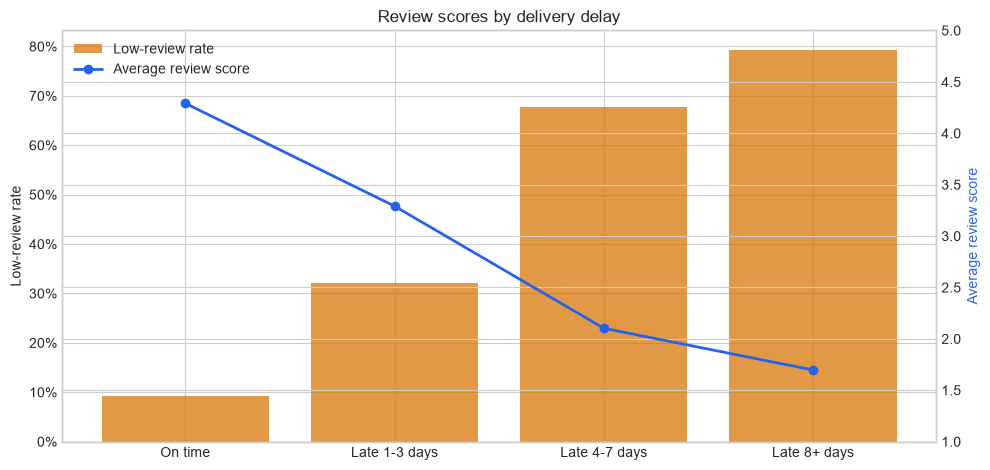

In [12]:
reviews = query("""
SELECT * FROM analysis.delivery_review_association
ORDER BY CASE delivery_group
    WHEN 'On time' THEN 1
    WHEN 'Late 1-3 days' THEN 2
    WHEN 'Late 4-7 days' THEN 3
    WHEN 'Late 8+ days' THEN 4
    ELSE 5
END
""")
display(reviews)

fig, ax1 = plt.subplots(figsize=(10, 4.8))
positions = range(len(reviews))
ax1.bar(positions, reviews['low_review_rate'], color=COLORS['amber'],
        alpha=0.75, label='Low-review rate')
ax1.set_ylabel('Low-review rate')
ax1.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax1.set_xticks(list(positions), reviews['delivery_group'])
ax2 = ax1.twinx()
ax2.plot(positions, reviews['average_review_score'], color=COLORS['blue'],
         marker='o', linewidth=2, label='Average review score')
ax2.set_ylabel('Average review score', color=COLORS['blue'])
ax2.set_ylim(1, 5)
ax1.set_title('Review scores by delivery delay')
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

The share of 1–2 star reviews rises with delay: **9.2%** on time, **32.1%** at 1–3 days late, **67.7%** at 4–7 days and **79.3%** at 8+ days. This is an association, not a measured effect.

## 10. Handover by order group and stage times by outcome

In [13]:
handover_sensitivity = query("""
SELECT population_name, candidate_count, eligible_count, excluded_count,
       breach_count, breach_rate, observation_coverage, interpretation
FROM analysis.handover_population_sensitivity
ORDER BY population_name
""")
display(handover_sensitivity)

stage_outcomes = query("""
SELECT * FROM analysis.fulfillment_stage_by_delivery_outcome
ORDER BY stage_name, delivery_outcome
""")
display(stage_outcomes)

,population_name,candidate_count,eligible_count,excluded_count,breach_count,breach_rate,observation_coverage,interpretation
0,DELIVERED_ONLY_SINGLE_SELLER,94939,94937,2,8531,0.090,1.000,Sensitivity view restricted to delivered orders
1,MULTI_SELLER_OBSERVABLE,2614,2614,0,113,0.043,1.000,Multi-seller orders; individual seller attribu...
2,PRIMARY_SINGLE_SELLER,96631,96032,599,8652,0.090,0.994,Main analysis group


,delivery_outcome,stage_name,eligible_order_count,excluded_order_count,p50_hours,p75_hours,p90_hours
0,Late,Approval to carrier handover,6506,25,73.563,150.248,335.209
1,On time,Approval to carrier handover,88332,1340,42.872,82.247,137.061
2,Late,Carrier handover to customer delivery,6530,1,628.882,839.601,"1,074.711"
3,On time,Carrier handover to customer delivery,89653,19,166.814,262.811,366.195
4,Late,Purchase to approval,6531,0,0.405,19.019,38.148
5,On time,Purchase to approval,89658,14,0.339,14.070,34.278
6,Late,Purchase to customer delivery,6531,0,749.916,960.225,"1,197.511"
7,On time,Purchase to customer delivery,89672,0,235.220,342.540,470.874


Late orders spent a median **26.2 days** between handover and delivery vs **7.0 days** for on-time orders, a gap of about **19 days**. The handover stage differs by about **1.3 days** (3.1 vs 1.8), so the carrier stage is where late and on-time orders differ most.

## 11. Priority sellers by customer state

In [14]:
seller_regions = query("""
SELECT seller_id, seller_state, customer_state, seller_priority_tier,
       handover_eligible_order_count, handover_breach_count,
       handover_breach_rate, late_delivery_rate, reason_codes
FROM analysis.mart_seller_region_investigation_queue
ORDER BY seller_priority_sort, handover_breach_count DESC, handover_breach_rate DESC
LIMIT 15
""")
display(seller_regions)

,seller_id,seller_state,customer_state,seller_priority_tier,handover_eligible_order_count,handover_breach_count,handover_breach_rate,late_delivery_rate,reason_codes
0,7c67e1448b00f6e969d365cea6b010ab,SP,SP,P1,385,117,0.304,0.076,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...
1,4a3ca9315b744ce9f8e9374361493884,SP,SP,P1,768,71,0.092,0.069,SUFFICIENT_REGION_VOLUME
2,1025f0e2d44d7041d6cf58b6550e0bfa,SP,SP,P1,313,61,0.195,0.067,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...
3,3d871de0142ce09b7081e2b9d1733cb1,SP,SP,P1,454,59,0.130,0.029,SUFFICIENT_REGION_VOLUME
4,88460e8ebdecbfecb5f9601833981930,PR,SP,P1,114,57,0.500,0.114,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...
5,53e4c6e0f4312d4d2107a8c9cddf45cd,SP,SP,P1,237,56,0.236,0.030,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...
6,7c67e1448b00f6e969d365cea6b010ab,SP,RJ,P1,174,54,0.310,0.156,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...
7,1f50f920176fa81dab994f9023523100,SP,SP,P1,493,53,0.108,0.028,SUFFICIENT_REGION_VOLUME
8,06a2c3af7b3aee5d69171b0e14f0ee87,MA,SP,P1,124,39,0.315,0.203,SUFFICIENT_REGION_VOLUME
9,8160255418d5aaa7dbdc9f4c64ebda44,SP,SP,P1,154,36,0.234,0.059,SUFFICIENT_REGION_VOLUME|ABOVE_STATE_LANE_BREA...


## 12. Delivery performance by product category

,category_name,delivery_sla_eligible_count,late_delivery_order_count,late_delivery_rate,late_delivery_rate_gap,average_late_days,end_to_end_p90_hours,average_review_score,low_review_rate
0,bed_bath_table,9267,689,0.074,0.006,10.951,558.586,3.971,0.168
1,health_beauty,8610,647,0.075,0.007,9.818,555.259,4.184,0.126
2,sports_leisure,7512,495,0.066,-0.002,10.768,533.750,4.168,0.130
3,furniture_decor,6258,449,0.072,0.004,11.102,556.101,4.012,0.166
4,computers_accessories,6517,416,0.064,-0.004,10.329,562.056,4.028,0.160
5,watches_gifts,5489,406,0.074,0.006,9.776,582.909,4.066,0.152
6,housewares,5734,308,0.054,-0.014,10.584,485.850,4.142,0.132
7,telephony,4086,291,0.071,0.003,9.241,572.201,4.004,0.154
8,auto,3801,278,0.073,0.005,12.349,540.174,4.093,0.144
9,toys,3781,243,0.064,-0.004,11.070,513.167,4.191,0.126


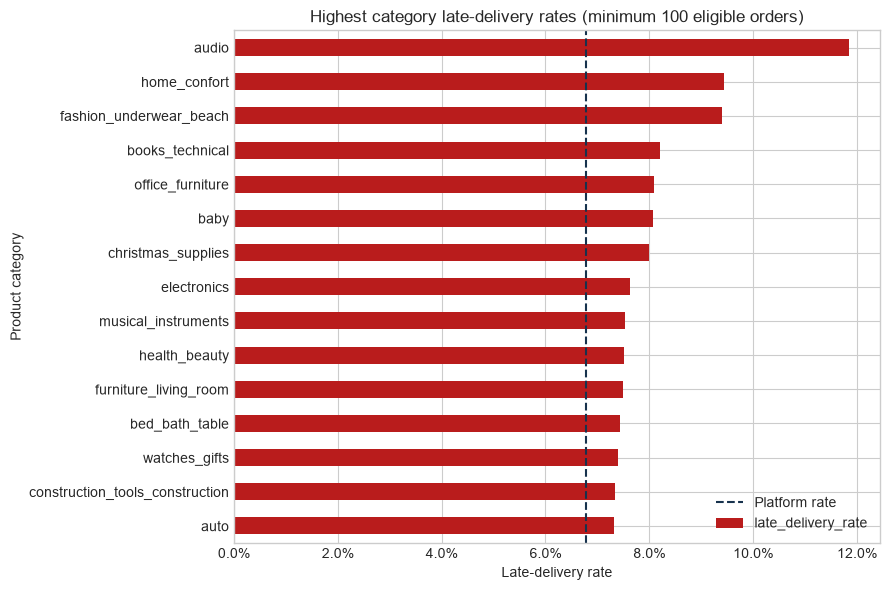

,category_name,stage_name,eligible_order_count,excluded_order_count,p50_hours,p90_hours
0,auto,Approval to carrier handover,3786,100,37.343,121.117
1,auto,Carrier handover to customer delivery,3800,86,169.695,453.100
2,auto,Purchase to approval,3886,0,0.350,34.410
3,auto,Purchase to customer delivery,3801,85,233.668,540.174
4,bed_bath_table,Approval to carrier handover,9236,176,45.693,136.671
5,bed_bath_table,Carrier handover to customer delivery,9264,148,176.018,472.767
6,bed_bath_table,Purchase to approval,9411,1,0.326,32.569
7,bed_bath_table,Purchase to customer delivery,9267,145,257.067,558.586
8,computers_accessories,Approval to carrier handover,6516,155,46.593,168.024
9,computers_accessories,Carrier handover to customer delivery,6515,156,174.667,449.795


In [15]:
categories = query("""
SELECT category_name, delivery_sla_eligible_count, late_delivery_order_count,
       late_delivery_rate, late_delivery_rate_gap, average_late_days,
       end_to_end_p90_hours, average_review_score, low_review_rate
FROM analysis.agg_category_performance
WHERE delivery_sla_eligible_count >= 100
ORDER BY late_delivery_order_count DESC, late_delivery_rate DESC
""")
display(categories.head(15))

category_rates = categories.nlargest(15, 'late_delivery_rate').sort_values('late_delivery_rate')
platform_late_rate = (
    float(categories.iloc[0]['late_delivery_rate'])
    - float(categories.iloc[0]['late_delivery_rate_gap'])
)
ax = category_rates.plot.barh(
    x='category_name', y='late_delivery_rate', figsize=(9, 6),
    color=COLORS['red'], legend=False
)
ax.axvline(
    platform_late_rate,
    color=COLORS['navy'], linestyle='--', label='Platform rate'
)
ax.set(title='Highest category late-delivery rates (minimum 100 eligible orders)',
       xlabel='Late-delivery rate', ylabel='Product category')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
plt.show()

category_stages = query("""
WITH high_late_volume AS (
    SELECT category_name
    FROM analysis.agg_category_performance
    WHERE delivery_sla_eligible_count >= 100
    ORDER BY late_delivery_order_count DESC
    LIMIT 10
)
SELECT stage.category_name, stage.stage_name, stage.eligible_order_count,
       stage.excluded_order_count, stage.p50_hours, stage.p90_hours
FROM analysis.category_fulfillment_stage_performance AS stage
INNER JOIN high_late_volume USING (category_name)
ORDER BY stage.category_name, stage.stage_name
""")
display(category_stages)

## 13. Data issues and how they're handled

,check_id,check_name,rows_tested,affected_count,handling
0,W001,Delivered orders with carrier handover before ...,96478,1350,Flag and exclude from pre-carrier duration
1,W002,Delivered orders with customer delivery before...,96478,23,Flag and exclude from carrier duration
2,W003,Delivered orders missing customer-delivery tim...,96478,8,Exclude from delivery SLA
3,W004,Orders containing multiple sellers,98666,1278,Exclude from primary seller attribution
4,W005,Orders containing multiple known categories,98666,727,Treat category counts as non-additive
5,W006,Orders containing multiple review rows,98673,547,Use deterministic representative review
6,W007,Orders missing valid customer ZIP-prefix coord...,99441,278,Exclude only from distance analysis
7,W008,Order-seller pairs with multiple shipping dead...,100010,0,Preserve item-level deadline logic
8,W009,Promised-day deliveries misclassified by times...,96470,1292,Use calendar-date comparison
9,W010,Order-seller pairs missing seller ZIP-prefix c...,100010,220,Exclude only from distance analysis


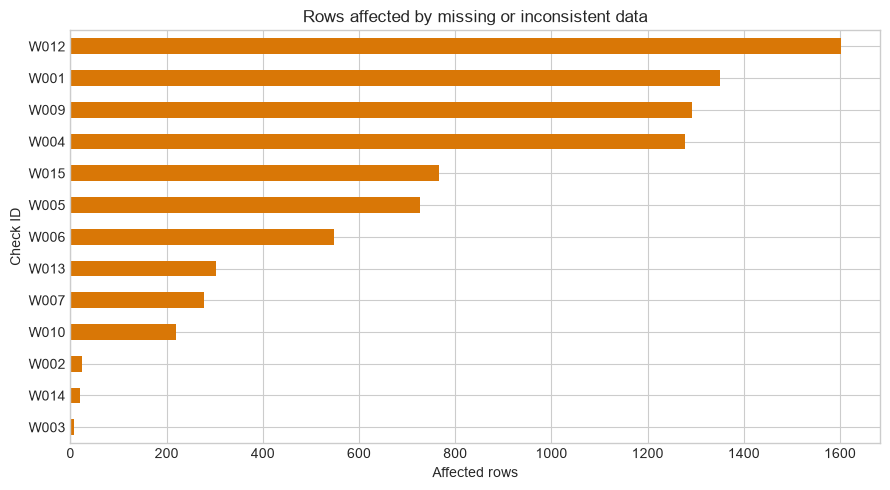

In [16]:
data_notes = query("""
SELECT check_id, check_name, rows_tested, affected_count, handling
FROM checks.data_notes
ORDER BY check_id
""")
display(data_notes)

active_notes = data_notes[data_notes['affected_count'] > 0].sort_values('affected_count')
ax = active_notes.plot.barh(
    x='check_id', y='affected_count', figsize=(9, 5),
    color=COLORS['amber'], legend=False
)
ax.set(title='Rows affected by missing or inconsistent data',
       xlabel='Affected rows', ylabel='Check ID')
plt.tight_layout()
plt.show()

## 14. Key findings

In [17]:
h = headline.iloc[0]
primary_orders = int(h['primary_orders'])
on_time_rate = float(h['on_time_delivery_rate'])
on_time_orders = int(h['on_time_orders'])
delivery_eligible = int(h['delivery_sla_eligible'])
handover_breaches = int(h['handover_breaches'])

modes = failure_modes.set_index('failure_mode')['order_count'].map(int)
late_met = modes['Handover met / Delivery late']
late_breached = modes['Handover breached / Delivery late']
late_single_seller = late_met + late_breached

stage_p50_days = (
    stage_outcomes.set_index(['stage_name', 'delivery_outcome'])['p50_hours']
    .map(float) / 24
)
carrier_late = stage_p50_days[('Carrier handover to customer delivery', 'Late')]
carrier_on_time = stage_p50_days[('Carrier handover to customer delivery', 'On time')]
handover_late = stage_p50_days[('Approval to carrier handover', 'Late')]
handover_on_time = stage_p50_days[('Approval to carrier handover', 'On time')]

p1 = queue[queue['priority_tier'] == 'P1']
p1_breaches = int(p1['handover_breach_count'].sum())

low_review = reviews.set_index('delivery_group')['low_review_rate'].map(float)
display(Markdown(f"""
- On-time delivery is **{on_time_rate:.1%}** ({on_time_orders:,} / {delivery_eligible:,})
  across **{primary_orders:,}** primary-period orders.
- Of **{late_single_seller:,}** late single-seller orders where both handover and delivery can be checked,
  **{late_met / late_single_seller:.1%}** ({late_met:,}) were handed over on time.
- Median carrier stage (handover → delivery): **{carrier_late:.1f}** days late vs
  **{carrier_on_time:.1f}** on time (gap about **{carrier_late - carrier_on_time:.0f}** days);
  approval → handover gap is **{handover_late - handover_on_time:.1f}** days.
- **{len(p1):,} P1 sellers** account for **{p1_breaches / handover_breaches:.1%}**
  ({p1_breaches:,} / {handover_breaches:,}) of late handovers.
- 1–2 star review rate: **{low_review['On time']:.1%}** on time,
  **{low_review['Late 1-3 days']:.1%}** at 1–3 days late, **{low_review['Late 4-7 days']:.1%}**
  at 4–7 days, **{low_review['Late 8+ days']:.1%}** at 8+ days.

These are descriptive comparisons; they don't show that sellers or carriers caused the delays.
"""))


- On-time delivery is **93.2%** (89,672 / 96,203)
  across **99,092** primary-period orders.
- Of **6,517** late single-seller orders where both handover and delivery can be checked,
  **72.2%** (4,708) were handed over on time.
- Median carrier stage (handover → delivery): **26.2** days late vs
  **7.0** on time (gap about **19** days);
  approval → handover gap is **1.3** days.
- **70 P1 sellers** account for **32.5%**
  (2,815 / 8,652) of late handovers.
- 1–2 star review rate: **9.2%** on time,
  **32.1%** at 1–3 days late, **67.7%**
  at 4–7 days, **79.3%** at 8+ days.

These are descriptive comparisons; they don't show that sellers or carriers caused the delays.
